In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [10]:
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

11490434/11490434 [==============================] - 3s 0us/step
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


In [11]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


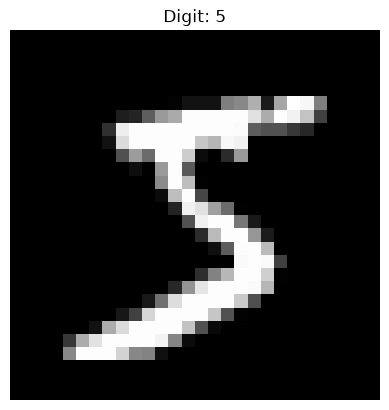

In [12]:
plt.imshow(X_train[0], cmap="gray")
plt.title(f"Digit: {y_train[0]}")
plt.axis("off")
plt.show()

In [13]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 32)                25120     
                                                                 
 dense_1 (Dense)             (None, 10)                330       
                                                                 
Total params: 25450 (99.41 KB)
Trainable params: 25450 (99.41 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [14]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    validation_split=0.1
)

Epoch 1/5


1688/1688 [==============================] - 30s 7ms/step - loss: 1.7101 - accuracy: 0.5734 - val_loss: 1.0730 - val_accuracy: 0.7593
Epoch 2/5
1688/1688 [==============================] - 6s 3ms/step - loss: 0.8758 - accuracy: 0.7839 - val_loss: 0.6448 - val_accuracy: 0.8610
Epoch 3/5
1688/1688 [==============================] - 6s 3ms/step - loss: 0.6197 - accuracy: 0.8425 - val_loss: 0.4790 - val_accuracy: 0.8917
Epoch 4/5
1688/1688 [==============================] - 6s 3ms/step - loss: 0.5061 - accuracy: 0.8661 - val_loss: 0.3987 - val_accuracy: 0.9028
Epoch 5/5
1688/1688 [==============================] - 5s 3ms/step - loss: 0.4459 - accuracy: 0.8804 - val_loss: 0.3544 - val_accuracy: 0.9085


In [15]:
loss, accuracy = model.evaluate(X_test, y_test)

print(f"Test accuracy: {accuracy:.2%}")

313/313 [==============================] - 1s 3ms/step - loss: 0.4037 - accuracy: 0.8938
Test accuracy: 89.38%


1/1 [==============================] - 1s 538ms/step


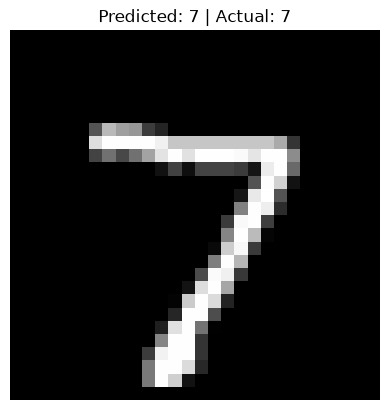

In [16]:
index = 0

prediction = model.predict(X_test[index:index + 1])
predicted_digit = np.argmax(prediction)

plt.imshow(X_test[index], cmap="gray")
plt.title(f"Predicted: {predicted_digit} | Actual: {y_test[index]}")
plt.axis("off")
plt.show()

In [17]:
model.save("digit_model.keras")